## Claim Verification Results on the Development partition of the gold-retrieved evidence

In [1]:
MODEL_NAME_MAPPING = {
    'Meta-Llama-3.1-70B-Instruct': 'Llama 3.1',
    'Mixtral-8x7B-Instruct-v0.1': 'Mixtral',
    'gpt-5.2': 'GPT 5.2',
    'Llama-4-Scout-17B-16E-Instruct': 'Llama 4',
    'Llama-3.2-3B-Instruct': 'Llama 3.2',
    'gemma-4-31B-it': 'Gemma 4'
}

# PARTITION = 'dev'
VERSION = '2026.03.03'
TRAIN_VERSION = '2026.03.03'
DATASET = 'civicfact'


In [2]:
import glob
import json
import re

configs = glob.glob('../configs/generation/*.json')

SYSTEM_PROMPT_TO_CONFIG = {}

for config in configs:
    m = re.match(r'.*config-(\d+).json$', config)
    assert m
    config_number = f'gen-{m.group(1)}'
    with open(config, 'r') as fh:
        data = json.load(fh)
    if 'system_prompt_file' in data:
        name = data['system_prompt_file'].split('/')[-1].replace('.md', '')
        SYSTEM_PROMPT_TO_CONFIG.setdefault(name, set()).add(config_number)
    else:
        SYSTEM_PROMPT_TO_CONFIG.setdefault('none', set()).add(config_number)

SYSTEM_PROMPT_TO_CONFIG

{'none': {'gen-1',
  'gen-10',
  'gen-11',
  'gen-15',
  'gen-16',
  'gen-17',
  'gen-2',
  'gen-3',
  'gen-4',
  'gen-5',
  'gen-6'},
 'chatgpt': {'gen-12', 'gen-19', 'gen-7'},
 'civic_editor': {'gen-18', 'gen-8', 'gen-9'},
 'civic_editor_mixtral': {'gen-13'},
 'civic_editor_llama3.1': {'gen-14'}}

In [3]:
import numpy as np
import subprocess
import seaborn as sns

sns.set_style('whitegrid')
from utils import add_bar_labels, pop_model_size, read_jsonl, savefig
from utils.metabar import plot_metadatabar_chart

def ci_95(series):
    return (series.quantile(0.025), series.quantile(0.975))

ERR_KWS={'linewidth': 1, 'color': '#00000099'}


def create_and_filter_model_names(df):
    df["model"] = df['filepath.model_dir'].str.split("__").str[-1].apply(lambda x: MODEL_NAME_MAPPING.get(x))
    df = df[~df.model.isna()]
    df.loc[~df['filepath.train_data_version'].isna(), 'model'] += ' (FT)'
    df.loc[df['filepath.train_dataset'] == 'civicfactx5000g8', 'model'] += ' expl-1'
    df.loc[df['filepath.train_dataset'] == 'civicfactxf1.0g8', 'model'] += ' expl'
    df.loc[df['filepath.train_dataset'] == 'civicfactchunk', 'model'] += ' expl/chunks'
    df.loc[df.model.str.contains('(FT)', regex=False), 'model'] += ' c' + df['filepath.config']
    return df


In [4]:
from utils import collect_filepath_metadata
import pandas as pd

inputs = []
for patt in [
    f'.*evaluations.*civicfact.*-{VERSION}/.*.processed.label_accuracy.*',
]:
    inputs.extend(subprocess.check_output(f"find ../results/claim_verification -regex '{patt}'", shell=True).decode().split('\n'))

inputs = [f.strip() for f in inputs if f.strip() and '_f0.' not in f]
print(f'found {len(inputs)} matching input files')

rows = []
for filename in inputs:
    meta = collect_filepath_metadata(filename)
    row = {'filename': filename, **{f'filepath.{m}': v for m, v in meta.items()}}
    rows.append(row)

df = pd.DataFrame.from_records(rows)
df = df[df['filepath.partition'].isin({'dev','test'})]


df = df.rename(columns={"freq": "dataset_size"})

for col in sorted({'filepath.train_prompt_template', 'filepath.eval_dataset','filepath.data_version', 'filepath.train_dataset', 'filepath.train_data_version', 'filepath.ret_model', 'filepath.embedding_mode',  'filepath.pairing_mode', 'filepath.prompt_template', 'filepath.chat_template', 'filepath.generation_config', 'filepath.subsample_filter'}):
    if col not in df:
        df[col] = None
    else:
        print(col, df[col].unique().tolist())

df = df[
    # (df['filepath.prompt_template'].fillna('none').isin({'none', 'labelfirst', 'verboselimit100'}))
    (df['filepath.data_version'].isin({VERSION}))
    & (df['filepath.train_data_version'].fillna('none').isin({TRAIN_VERSION, 'none'}))
    & (~df['filepath.train_dataset'].isin({'civicfactx5000g8'}))
    & (df['filepath.subsample_fraction'].astype(float).fillna(1) == 1)
    # & (df['filepath.partition'] == 'dev')
    # & (~df['filepath.config'].isin({'17', '18', '19', '15'}))
]


df = create_and_filter_model_names(df)
print(df.model.value_counts())
df['filepath.subsample_filter'] = df['filepath.subsample_filter'].fillna('all')


def is_best_configs(row):
    if not pd.isnull(row['filepath.ret_model']) and row['filepath.ret_model'] not in {'medcpt-goat', 'qwen-mongoose', '', 'head-oracle'}:
        return False
    uses_explanation_data = 'xf1.0g8' in row['filepath.eval_dataset']
    # fine tuned models
    if row['filepath.train_dataset'] == 'civicfactchunk':
        status = all([
            row['model'] == 'Llama 3.2 (FT) expl/chunks c16'
        ])
    elif not pd.isnull(row['filepath.train_dataset']):
        status = False
    elif row['model'] == 'Mixtral':
        status = all([
            row['filepath.prompt_template']  == 'verifyevidence',
            float(row['filepath.examples']) == 30,
            row['filepath.generation_config'] in SYSTEM_PROMPT_TO_CONFIG['chatgpt'],
            not uses_explanation_data
        ])
    elif row['model'] == 'Llama 3.1':
        status = all([
                row['filepath.prompt_template']  == 'verifyevidence',
                float(row['filepath.examples']) == 15,
                row['filepath.generation_config'] in SYSTEM_PROMPT_TO_CONFIG['chatgpt'],
                uses_explanation_data
            ])
    elif row['model'] == 'Llama 4':
        status = all([
            row['filepath.prompt_template']  == 'verifypassages',
            float(row['filepath.examples']) == 30,
            row['filepath.generation_config'] in SYSTEM_PROMPT_TO_CONFIG['none'],
            not uses_explanation_data
        ])
    elif row['model'] == 'GPT 5.2':
        status = all([
            row['filepath.prompt_template']  == 'jsonexampleslimit200',
            float(row['filepath.examples']) == 30,
            row['filepath.generation_config'] in SYSTEM_PROMPT_TO_CONFIG['none'],
            not uses_explanation_data
        ])
    elif row['model'] == 'Llama 3.2':
        status = all([
            row['filepath.prompt_template']  == 'jsonexampleslimit200',
            float(row['filepath.examples']) == 3,
            row['filepath.generation_config'] in SYSTEM_PROMPT_TO_CONFIG['chatgpt'],
            uses_explanation_data
        ])
    elif row['model'] == 'Gemma 4':
        status = all([
            row['filepath.prompt_template']  == 'jsonexampleslimit200',
            float(row['filepath.examples']) == 15,
            row['filepath.generation_config'] in SYSTEM_PROMPT_TO_CONFIG['none'],
            not uses_explanation_data
        ])
    else:

        print('\n\nmissing status for model run config:')
        for c, v in dict(row).items():
            if c in ['model', 'filepath.train_dataset', 'filepath.train_data_version', 'filepath.config', 'filepath.generation_config', 'filepath.model_dir', 'filepath.eval_dataset']:
                print(c, v)

        raise NotImplementedError('model best params not known')
    if not status:
        print('\nrejected configuration')
        for c, v in dict(row).items():
            if c in ['model', 'filepath.train_dataset', 'filepath.train_data_version', 'filepath.config', 'filepath.generation_config', 'filepath.model_dir', 'filepath.eval_dataset']:
                print(c, v)
    return status





# filter on model best param picks
df = df[df.apply(is_best_configs, axis=1)]



print(df.filename.nunique(), 'files after filtering')


previous_count = df[['model', 'filepath.train_data_version', 'filepath.data_version', 'model', 'filepath.eval_dataset']].drop_duplicates().shape[0]
print('final selected files:', df.filename.nunique())
df[['model', 'filepath.train_dataset', 'filepath.config', 'filepath.data_version', 'filepath.eval_dataset', 'filepath.ret_model']].drop_duplicates().sort_values(['model', 'filepath.train_dataset', 'filepath.data_version', 'filepath.eval_dataset'])

found 269 matching input files
filepath.chat_template ['default']
filepath.data_version ['2026.03.03']
filepath.eval_dataset ['civicfactpairs', 'civicfact', 'civicfactx5000g8', 'civicfactxf1.0g8', 'civicfactxf1.0g8pairs']
filepath.generation_config ['gen-5', 'gen-2', 'gen-12', 'gen-16', 'gen-11']
filepath.prompt_template ['jsonlimit200', 'verifyevidencetrain', 'jsonexampleslimit200', 'verifyevidence', 'verifypassages']
filepath.ret_model ['medcpt-goat', nan, 'grand-bat', 'qwen-mongoose', 'head', 'head-oracle', 'random42', 'oracle']
filepath.subsample_filter [nan, 'hard', 'realclaims']
filepath.train_data_version ['2026.03.03', nan]
filepath.train_dataset ['civicfact', 'civicfactx5000g8', 'civicfactxf1.0g8', 'civicfactchunk', nan]
filepath.train_prompt_template ['jsonlimit200', 'verifyevidencetrain', nan]
model
Llama 3.2 (FT) expl/chunks c16    30
Gemma 4                           28
Llama 3.1                         27
Llama 4                           27
GPT 5.2                       

,model,filepath.train_dataset,filepath.config,filepath.data_version,filepath.eval_dataset,filepath.ret_model
243,GPT 5.2,NaN,NaN,2026.03.03,civicfact,NaN
246,GPT 5.2,NaN,NaN,2026.03.03,civicfactpairs,head-oracle
253,GPT 5.2,NaN,NaN,2026.03.03,civicfactpairs,medcpt-goat
255,GPT 5.2,NaN,NaN,2026.03.03,civicfactpairs,qwen-mongoose
222,Gemma 4,NaN,NaN,2026.03.03,civicfact,NaN
216,Gemma 4,NaN,NaN,2026.03.03,civicfactpairs,medcpt-goat
218,Gemma 4,NaN,NaN,2026.03.03,civicfactpairs,qwen-mongoose
220,Gemma 4,NaN,NaN,2026.03.03,civicfactpairs,head-oracle
115,Llama 3.1,NaN,NaN,2026.03.03,civicfactxf1.0g8,NaN
119,Llama 3.1,NaN,NaN,2026.03.03,civicfactxf1.0g8pairs,head-oracle


In [5]:
# Now load the selected files


df = read_jsonl(*df.filename.tolist(), add_filename=True, add_filepath_metadata=True)

print(df['filepath.model_dir'].value_counts())

df = create_and_filter_model_names(df)

print(df['filepath.model_dir'].value_counts())
df['subset'] = df['filepath.subsample_filter'] = df['filepath.subsample_filter'].fillna('all')
df['retrieval'] =  df['filepath.ret_model']
df.loc[df.retrieval == 'random42', 'retrieval'] = 'Random'
df.loc[df.retrieval == 'head-oracle', 'retrieval'] = 'Oracle'
df.loc[~df['filepath.eval_dataset'].str.contains('pairs'), 'retrieval'] = 'Human'
df.loc[df['filepath.eval_dataset'] == 'civicfactft', 'retrieval'] = 'Full-Text'
print(df.columns.tolist())
df.head()

filepath.model_dir
meta-llama__Llama-3.2-3B-Instruct             48048
google__gemma-4-31B-it                        24024
openai__gpt-5.2                               24024
mistralai__Mixtral-8x7B-Instruct-v0.1         16016
meta-llama__Llama-4-Scout-17B-16E-Instruct    13013
meta-llama__Meta-Llama-3.1-70B-Instruct       12012
Name: count, dtype: int64
filepath.model_dir
meta-llama__Llama-3.2-3B-Instruct             48048
google__gemma-4-31B-it                        24024
openai__gpt-5.2                               24024
mistralai__Mixtral-8x7B-Instruct-v0.1         16016
meta-llama__Llama-4-Scout-17B-16E-Instruct    13013
meta-llama__Meta-Llama-3.1-70B-Instruct       12012
Name: count, dtype: int64
['accuracy', 'assignment.round', 'boot_i', 'claims', 'class_NEI.accuracy', 'class_NEI.fbeta_score', 'class_NEI.freq', 'class_NEI.precision', 'class_REVISIONS.accuracy', 'class_REVISIONS.fbeta_score', 'class_REVISIONS.freq', 'class_REVISIONS.precision', 'class_SUPPORTS.accuracy', 'class

,accuracy,assignment.round,boot_i,claims,class_NEI.accuracy,class_NEI.fbeta_score,class_NEI.freq,class_NEI.precision,class_REVISIONS.accuracy,class_REVISIONS.fbeta_score,...,filepath.ret_task,filepath.ret_train_data_format,filepath.ret_train_data_version,filepath.ret_train_dataset,filepath.ret_train_query_template,filepath.compute_location,filepath.quantized,model,subset,retrieval
0,0.882126,1,NaN,845,0.930435,0.952522,345.0,0.975684,0.942029,0.864362,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Llama 3.2 (FT) expl/chunks c16,all,Human
1,0.887923,1,0.0,567,0.928144,0.943683,334.0,0.959752,0.967836,0.877984,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Llama 3.2 (FT) expl/chunks c16,all,Human
2,0.881159,1,1.0,580,0.931818,0.959064,352.0,0.987952,0.918478,0.863346,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Llama 3.2 (FT) expl/chunks c16,all,Human
3,0.862802,1,2.0,576,0.937500,0.953101,336.0,0.969231,0.920904,0.840206,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Llama 3.2 (FT) expl/chunks c16,all,Human
4,0.877295,1,3.0,556,0.909639,0.937888,332.0,0.967949,0.933148,0.864516,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Llama 3.2 (FT) expl/chunks c16,all,Human


In [6]:
# pick the best training config
generation_configurable_params = ['filepath.prompt_template', 'filepath.generation_config']

## What if we only look at examples from the "hard" subset?

['accuracy', 'assignment.round', 'boot_i', 'claims', 'class_NEI.accuracy', 'class_NEI.fbeta_score', 'class_NEI.freq', 'class_NEI.precision', 'class_REVISIONS.accuracy', 'class_REVISIONS.fbeta_score', 'class_REVISIONS.freq', 'class_REVISIONS.precision', 'class_SUPPORTS.accuracy', 'class_SUPPORTS.fbeta_score', 'class_SUPPORTS.freq', 'class_SUPPORTS.precision', 'correct', 'documents', 'filename', 'filepath.chat_template', 'filepath.config', 'filepath.data_version', 'filepath.eval_dataset', 'filepath.examples', 'filepath.generation_config', 'filepath.method', 'filepath.model_dir', 'filepath.partition', 'filepath.prompt_template', 'filepath.ret_length', 'filepath.ret_model', 'filepath.ret_query_template', 'filepath.subsample_filter', 'filepath.subsample_fraction', 'filepath.subsample_seed', 'filepath.task', 'filepath.train_chat_template', 'filepath.train_data_version', 'filepath.train_dataset', 'filepath.train_examples', 'filepath.train_prompt_template', 'freq', 'macro_avg.accuracy', 'macro

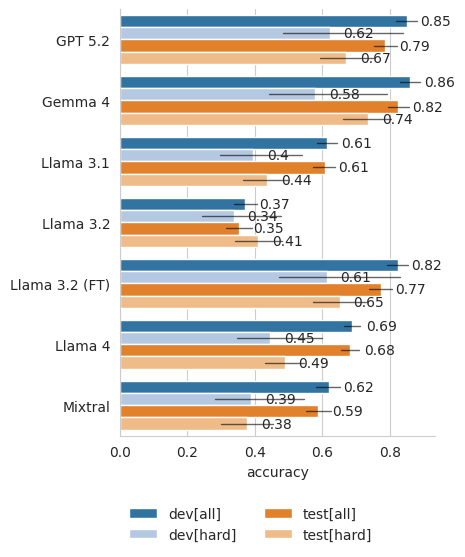

In [13]:
from matplotlib import pyplot as plt

from utils.fig import generate_hue_map
import pandas as pd

fig_df =  df.copy()
fig_df['row_index'] = fig_df.index.tolist()
fig_df = fig_df[ fig_df['filepath.subsample_filter'].isin({'all', 'hard'})]
fig_df['subset'] = fig_df['filepath.partition'].fillna('') + '[' + fig_df['filepath.subsample_filter'].fillna('') + ']'


metric = 'accuracy'
fig_df['ret_model'] = fig_df['filepath.ret_model'].fillna('none')
fig_df['ret_length'] = fig_df['filepath.ret_length'].fillna('L5000').astype(str)

fig_df = fig_df[(fig_df['ret_length'] != 'L10000')]
# fig_df = fig_df[~fig_df.model.isin({'Llama 3.2 [1B]', 'Llama 3.2 [1B]', 'Llama 3.2 [1B] (FT)',  'Llama 3.2 [1B] (FT)', 'Llama 3.1', 'Llama 3.1 (FT)'})]


fig_df['class_non-NEI.' + metric] = (fig_df['class_SUPPORTS.' + metric] + fig_df['class_REVISIONS.' + metric] ) / 2
fig_df['class_non-NEI.freq'] = fig_df['class_SUPPORTS.freq'] + fig_df['class_REVISIONS.freq']
fig_df.loc[fig_df['subset'] == 'hard', 'macro_avg.' + metric] = fig_df['class_non-NEI.' + metric]
fig_df.loc[fig_df['subset'] == 'hard', 'macro_avg.freq'] = fig_df['class_non-NEI.freq']
# the HARD dataset has too few samples for the macro_avg to a reasonable est, use non_NEI instead

fig_df = fig_df[fig_df.retrieval.isin({'Oracle'})]


fig_df['row_index'] = fig_df.index.tolist()
print(fig_df.columns.tolist())
counts_df  = pd.melt(
    fig_df.drop(columns='freq'),
    id_vars=[ 'retrieval', 'model', 'row_index', 'subset', 'filepath.partition'],
    value_vars=['class_SUPPORTS.freq', 'class_NEI.freq', 'class_REVISIONS.freq', 'macro_avg.freq'],
    var_name='label',
    value_name='freq'
)
counts_df.loc[counts_df.label == 'macro_avg.freq', 'label'] = 'class_average.'
counts_df['label'] = counts_df.label.str.extract(r'class_([^.]+)\.')
print(counts_df.label.unique())

fig_df = pd.melt(
    fig_df.drop(columns=[metric] if metric in fig_df.columns else []),
    id_vars=['retrieval', 'model', 'row_index', 'subset', 'filepath.partition'],
    value_vars=['class_SUPPORTS.' + metric, 'class_NEI.' + metric, 'class_REVISIONS.' + metric, 'macro_avg.' + metric],
    var_name='label',
    value_name=metric
)
fig_df.loc[fig_df.label == 'macro_avg.' + metric, 'label'] = 'class_average.'
fig_df['label'] = fig_df.label.str.extract(r'class_([^.]+)\.')

print(fig_df.label.unique())

counts_df = counts_df[(counts_df.freq > 10) | (counts_df.freq.isna())]  # filter out classes with only 1-2 examples as they will make misleading plot values
fig_df = fig_df.merge(counts_df)

hue_map = {
    'NEI': '#c5b0d5',
    'SUPPORTS [hard]': '#2ca02c',
    'SUPPORTS': '#98df8a',
    'REVISIONS [hard]':  '#ff7f0e',
    'REVISIONS': '#ffbb78',
    'average':  '#aec7e8',
    'non-NEI [hard]':'#1f77b4',
    'Human': '#1f77b4',
    'Oracle (chunks)': '#2ca02c',
    'Random (chunks)': '#ff7f0e',
    'NO LABEL': '#D3D3D3'
}

# fig_df = fig_df[(fig_df.subset != 'hard') | (fig_df['label'].isin({'non-NEI'}))]
# fig_df.loc[fig_df.subset == 'hard', 'label'] += ' [hard]'
# fig_df.loc[fig_df.subset == 'realclaims', 'label'] += ' [manual]'
# fig_df = fig_df[fig_df.label != 'non-NEI']  # only makes sense for hard dataset where there are so few NEI examples
# fig_df = fig_df[fig_df.label != 'average [hard]']  # only makes sense for hard dataset where there are so few NEI examples


# fig_df = fig_df[(fig_df.retrieval != 'Random') | (fig_df.label.isin({'SUPPORTS [hard]', 'NEI', 'non-NEI [hard]'}))]



if fig_df[fig_df.model.str.contains('(FT)', regex=False)].model.nunique() == 1:
    print(fig_df.model.unique())
    fig_df['model'] = fig_df['model'].str.replace(r'\[\dB\] \(FT\).*', '(FT)', regex=True)



# fig = sns.catplot(fig_df.sort_values(['subset', 'model', 'label','retrieval']), x=metric, y='model', kind='bar', col='label', hue='subset', palette='tab20',  errorbar=ci_95, err_kws=ERR_KWS)
# add_bar_labels(fig, fmt=lambda x: round(x, 2), padding=10)
# fig.set_ylabel('')

fig_df['model'] = fig_df.model.str.replace(r'\(FT\).*', '(FT)', regex=True)

fig = sns.catplot(fig_df[fig_df.label == 'average'].sort_values(['subset', 'model', 'label','retrieval']), x=metric, y='model', kind='bar', hue='subset', palette='tab20',  errorbar=ci_95, err_kws=ERR_KWS)
add_bar_labels(fig, fmt=lambda x: round(x, 2), padding=10)
fig.set(ylabel='')
sns.move_legend(
    fig,
    loc="upper center",
    bbox_to_anchor=(0.5, 0),
    ncol=2,
    title=None,
)

accuracy freq
model          filepath.partition subset                   
GPT 5.2        dev                dev[all]    0.850235  NaN
                                  dev[hard]   0.622187  NaN
               test               test[all]   0.785540  NaN
                                  test[hard]  0.670189  NaN
Gemma 4        dev                dev[all]    0.861111  NaN
                                  dev[hard]   0.578379  NaN
               test               test[all]   0.824992  NaN
                                  test[hard]  0.735118  NaN
Llama 3.1      dev                dev[all]    0.614300  NaN
                                  dev[hard]   0.395521  NaN
               test               test[all]   0.606897  NaN
                                  test[hard]  0.437334  NaN
Llama 3.2      dev                dev[all]    0.372464  NaN
                                  dev[hard]   0.337432  NaN
               test               test[all]   0.352729  NaN
                                  test[hard]  0.410427  NaN
Llama 3.2 (FT) dev                dev[all]    0.823494  NaN
                                  dev[hard]   0.612697  NaN
               test               test[all]   0.774247  NaN
                                  test[hard]  0.651221  NaN
Llama 4        dev                dev[all]    0.687501  NaN
                                  dev[hard]   0.445969  NaN
               test               test[all]   0.683414  NaN
                                  test[hard]  0.488748  NaN
Mixtral        dev                dev[all]    0.619746  NaN
                                  dev[hard]   0.388044  NaN
               test               test[all]   0.587281  NaN
                                  test[hard]  0.377659  NaN

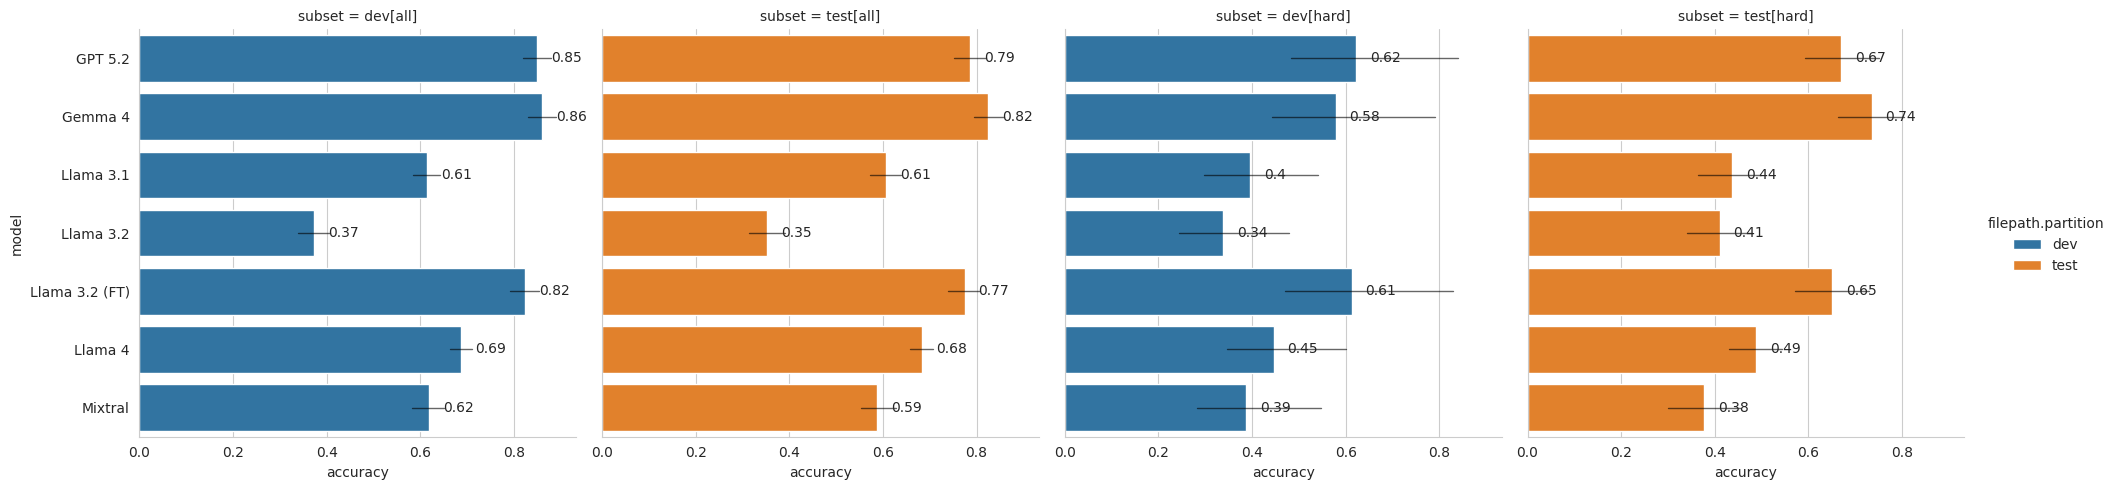

In [8]:
fig_df = fig_df[fig_df.label == 'average']

fig = sns.catplot(fig_df.sort_values(['model', 'label', 'retrieval']), x=metric, y='model', kind='bar', col='subset',  hue='filepath.partition',   errorbar=ci_95, err_kws=ERR_KWS)
add_bar_labels(fig, fmt=lambda x: round(x, 2), padding=10)

fig_df.groupby(['model', 'filepath.partition', 'subset']).agg({'accuracy': 'mean', 'freq': 'mean'})

['Llama 3.2 (FT) expl/chunks c16', 'Llama 3.1', 'Llama 3.2', 'Mixtral', 'Llama 4', 'Gemma 4', 'GPT 5.2']
['Llama 3.2 (FT)', 'Llama 3.2', 'Gemma 4', 'GPT 5.2']
<ArrowStringArray>
['Llama 3.2 (FT)', 'Llama 3.2', 'Gemma 4', 'GPT 5.2']
Length: 4, dtype: str


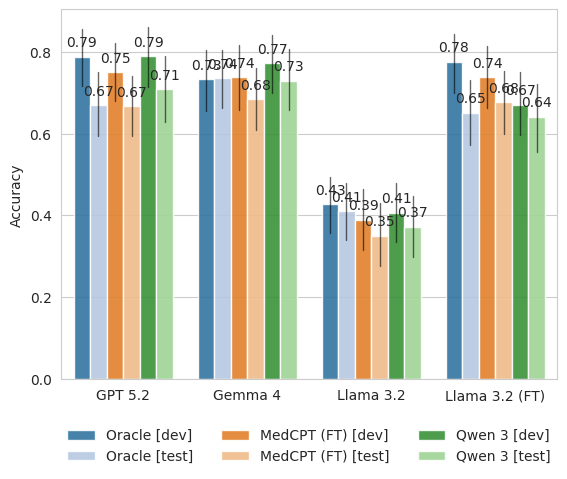

In [22]:

print(df['model'].unique().tolist())

fig_df =  df.copy()
fig_df['model'] = fig_df.model.str.replace(r'\(FT\).*', '(FT)', regex=True)
fig_df = fig_df[fig_df.subset != 'realclaims']
fig_df = fig_df[
    (fig_df.retrieval.isin({'Oracle', 'qwen-mongoose', 'medcpt-goat'}))
    & (~fig_df.model.isin({'Llama 3.1', 'Mixtral', 'Llama 4'}))
    & (fig_df['filepath.ret_length'].fillna('L5000') == 'L5000')
    & (fig_df['filepath.config'].fillna('16') == '16')
]
print(fig_df['model'].unique().tolist())
fig_df['ret_model'] = fig_df['filepath.ret_model'].fillna('none')
# fig_df.loc[fig_df.retrieval == 'qwen-mongoose', 'retrieval'] = 'Qwen3-reranker [8B]'
# fig_df.loc[fig_df.retrieval == 'medcpt-goat', 'retrieval'] = 'MedCPT (FT)'
if fig_df[fig_df.model.str.contains('(FT)', regex=False)].model.nunique() == 1:
    print(fig_df.model.unique())
    fig_df['model'] = fig_df['model'].str.replace(r'\[\d+B\] \(FT\).*', '(FT)', regex=True)

fig_df.loc[fig_df.retrieval == 'Oracle', 'retrieval'] = 'Oracle'
fig_df.loc[fig_df.retrieval == 'qwen-mongoose', 'retrieval'] = 'Qwen 3'
fig_df.loc[fig_df.retrieval == 'medcpt-goat', 'retrieval'] = 'MedCPT (FT)'

# only one NEI example which badly skews the average if included
fig_df.loc[fig_df.subset == 'hard', 'macro_avg.accuracy'] = (fig_df['class_SUPPORTS.accuracy'] + fig_df['class_REVISIONS.accuracy'] ) / 2

retrieval_order = ['Human', 'Oracle', 'MedCPT (FT)', 'Qwen 3']
fig_df['ret_order'] = fig_df.retrieval.apply(lambda r: retrieval_order.index(r))
fig_df = fig_df.sort_values(['ret_order', 'model'])

fig_df['subset'] = fig_df['filepath.partition'] + '[' + fig_df['filepath.subsample_filter'].fillna('all') + ']'
MODEL_HUE_MAP = generate_hue_map(sorted(fig_df.model.unique()), 'tab10')
fig_df.loc[fig_df.subset == 'hard', 'retrieval'] += ' [hard]'
fig_df.loc[fig_df.subset == 'realclaims', 'retrieval'] += ' [real]'

fig_df['retrieval'] = fig_df['retrieval'] + ' [' + fig_df['filepath.partition'].fillna('all') + ']'

# fig_df = fig_df[fig_df.model.isin({'Llama 3.1'})]
fig = sns.barplot(fig_df[fig_df['filepath.subsample_filter'] == 'hard'].sort_values(['ret_order', 'retrieval']), y='macro_avg.accuracy', x='model', hue='retrieval', alpha=0.9, errorbar=ci_95, err_kws=ERR_KWS, palette='tab20')
add_bar_labels(fig, fmt=lambda x: round(x, 2), padding=5)
fig.set(ylabel='Accuracy', xlabel='')
sns.move_legend(
    fig,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=3,
    title=None,
    frameon=False
)